In [1]:
!wget -q -c -O rev1-OmniAligner-rotation-crop-20261118.tar.gz https://github.com/huboqiang/omnialigner/releases/download/rev1/rev1-OmniAligner-rotation-crop-20261118.tar.gz
!git clone --quiet --depth 1 --branch rev1 https://github.com/huboqiang/omnialigner.git omnialigner-rev1

In [2]:
import sys
assert (3, 10) <= sys.version_info[:2] < (3, 12), "Use a fresh Python 3.10 or 3.11 Jupyter kernel."
!"{sys.executable}" -m pip install -q numpy==1.26.0 scipy==1.15.3 pandas==2.1.1 scikit-learn==1.4.2 matplotlib==3.9.1 seaborn==0.13.2

# OmniAligner: rotation/crop scoring from saved coordinates

Recompute **all 748 configuration–condition results**, the six-metric rankings,
and the rotation / crop / mean–variance figure from released NPZ inputs.
The metric functions and calculation loops are shown below.

Two fixed section pairs are used: DLPFC 151673→151674 and MHPR 0.04→0.09.
Each has 25 rotation settings (0°–360°, every 15°) and nine nominal retained
x-ranges (20%–100%). Eleven configurations represent nine algorithm families.
OmniAligner has 68 fixed-400-step outputs; four previously failed crop conditions
were rerun with isotropic coarse transforms. The other 64 are unchanged.

This notebook replays **saved registration coordinates**, rather than rerunning
agent matching or optimization. Original measured expression, labels and cell
identities are retained. Missing gene metrics remain NA; no genes or cases are
removed to improve a score. The original annotation-assisted fitting conditions
are not independent anatomical ground truth. Perturbations are technical settings,
not biological replicates.

In [3]:
from pathlib import Path
import hashlib, json, os, tarfile, time, warnings
os.environ.setdefault("OMP_NUM_THREADS", "4")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "4")
os.environ.setdefault("MKL_NUM_THREADS", "4")
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.spatial import cKDTree
from scipy.stats import pearsonr
from sklearn.feature_selection import mutual_info_regression
from IPython.display import display, Image

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(8 * 1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

archive = Path("rev1-OmniAligner-rotation-crop-20261118.tar.gz").resolve()
checkout = Path("omnialigner-rev1").resolve()
assert archive.is_file() and (checkout / ".git").is_dir()
assert sha256(archive) == "4e01c2dd154820de82547cd67ade34cd1622c1ecb0a5c4bc1fd249fc6da9dd79", "Download checksum mismatch"
DATA_ROOT = checkout / "benchmarks/rev1/OmniAligner/data/perturbations_20261118"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
with tarfile.open(archive, "r:gz") as bundle:
    for member in bundle.getmembers():
        target = (DATA_ROOT / member.name).resolve()
        assert target.is_relative_to(DATA_ROOT) and (member.isfile() or member.isdir())
    bundle.extractall(DATA_ROOT)
manifest = json.loads((DATA_ROOT / "manifest.json").read_text())
assert manifest["complete"] and len(manifest["coordinates"]) == 748
for name, digest in manifest["files_sha256"].items():
    assert sha256(DATA_ROOT / name) == digest, name
OUTPUT_ROOT = Path("perturbation_reproduced").resolve()
OUTPUT_ROOT.mkdir(exist_ok=True)
METRICS = ["PCC", "CosSim", "SSIM", "MI", "MSE", "Region"]
METHODS = manifest["methods"]
assert len(METHODS) == 11 and len(set(manifest["method_families"].values())) == 9
print("Verified public archive and", len(manifest["coordinates"]), "aligned-coordinate NPZ files.")

Verified public archive and 748 aligned-coordinate NPZ files.


## Load the unchanged expression, labels and cell identities

The cohort NPZs contain full original measured matrices as CSR components.
Only the fixed evaluation columns are loaded into the scoring arrays. The ordered
gene arguments retain duplicates: 123 for DLPFC and 155 for MHPR.

In [4]:
cohorts = {}
for record in manifest["datasets"]:
    dataset = record["dataset"]
    source = {}
    with np.load(DATA_ROOT / record["cohort_path"], allow_pickle=False) as raw:
        source["evaluation_genes"] = raw["evaluation_genes"].astype(str)
        for side in ["reference", "moving"]:
            X = sp.csr_matrix((raw[side+"_X_data"], raw[side+"_X_indices"],
                               raw[side+"_X_indptr"]), shape=tuple(raw[side+"_X_shape"]))
            columns = raw[side+"_evaluation_gene_indices"]
            assert np.array_equal(raw[side+"_var_names"][columns], source["evaluation_genes"])
            source[side] = dict(expression=X[:, columns].toarray(),
                ids=raw[side+"_ids"].astype(str), labels=raw[side+"_region_codes"],
                missing=raw[side+"_region_missing"], raw_xy=raw[side+"_raw_coords"])
            if side+"_original_source_coords" in raw.files:
                source[side]["original_source_xy"] = raw[side+"_original_source_coords"]
    cohorts[dataset] = source
display(pd.DataFrame([{ "Dataset": r["dataset"], "Reference cells": r["reference_cells"],
    "Moving cells": r["moving_cells"], "Gene arguments": len(r["evaluation_genes"]),
    "Distinct arguments": len(set(r["evaluation_genes"]))} for r in manifest["datasets"]]))
task_index = {(t["dataset"], t["condition"]): t for t in manifest["tasks"]}

,Dataset,Reference cells,Moving cells,Gene arguments,Distinct arguments
0,DLPFC,3611,3635,123,117
1,MHPR,5488,5557,155,155


## The input perturbations

These are the original SABench coordinate operations. Rotation is about the
coordinate mean, using a row-vector clockwise rotation. Cropping uses **x < threshold**,
including for the 100% reference: the upper boundary is not silently restored.
The nominal x-range is not a tissue-overlap area or retained-cell percentage.

In [5]:
def rotate_coordinates(xy, degrees):
    center = np.mean(xy, axis=0)
    theta = np.radians(degrees)
    rotation = np.array([[np.cos(theta), -np.sin(theta)],
                         [np.sin(theta),  np.cos(theta)]])
    return np.dot(xy - center, rotation) + center

def crop_indices(xy, percent):
    x = xy[:, 0]
    threshold = x.min() + (x.max() - x.min()) * (percent / 100)
    return np.where(x < threshold)[0]

for task in manifest["tasks"]:
    cohort = cohorts[task["dataset"]]
    with np.load(DATA_ROOT / task["input_path"], allow_pickle=False) as saved:
        for side in ["reference", "moving"]:
            raw = cohort[side].get("original_source_xy", cohort[side]["raw_xy"])
            if task["perturbation"] == "rotation":
                rows = np.arange(len(raw))
                xy = rotate_coordinates(raw, 0 if side == "reference" else task["parameter"])
            else:
                rows = crop_indices(raw, 100 if side == "reference" else task["parameter"])
                xy = raw[rows]
            np.testing.assert_array_equal(rows, saved[side+"_indices"])
            np.testing.assert_allclose(xy, saved[side+"_coords"], rtol=0, atol=1e-9)
print("All 68 perturbed input pairs reconstructed from the original coordinate operations.")

All 68 perturbed input pairs reconstructed from the original coordinate operations.


## Six visible metric functions

PCC, cosine similarity, SSIM, MI and expression MSE use the original shared 10×10
overlap grid. Region uses moving-to-reference nearest-neighbor label agreement
inside the closed overlap box. MSE is lower-is-better; the other five are higher-is-better.

Grid means are computed once per gene, preserving the original pandas mean and
expression dtype; each metric receives the same pair of grid vectors. SSIM divides
each gene's vector by its own maximum. MI resets the original seed to zero.
Native insufficient-grid fallbacks are recorded but excluded from eligible ranks.

### Shared spatial bins

In [6]:
def shared_grid(reference_xy, moving_xy):
    """Original 10 x 10 overlap bins, half-open boundaries and density rule."""
    xy = (reference_xy, moving_xy)
    low = np.maximum(reference_xy.min(0), moving_xy.min(0))
    high = np.minimum(reference_xy.max(0), moving_xy.max(0))
    boxes = []
    for i in range(10):
        for j in range(10):
            x_start = low[0] + i * (high[0] - low[0]) / 10
            y_start = low[1] + j * (high[1] - low[1]) / 10
            boxes.append((x_start, x_start + (high[0] - low[0]) / 10,
                          y_start, y_start + (high[1] - low[1]) / 10))

    def inside(points, box):
        x_start, x_end, y_start, y_end = box
        return ((points[:, 0] >= x_start) & (points[:, 0] < x_end)
                & (points[:, 1] >= y_start) & (points[:, 1] < y_end))

    masks = [[inside(points, box) for box in boxes] for points in xy]
    counts = [[mask.sum() for mask in side] for side in masks]
    threshold = min(np.mean(counts[0]), np.mean(counts[1])) / 2
    labels = [np.full(len(points), None, dtype=object) for points in xy]
    counter = 1
    for index in range(100):
        keep = counts[0][index] >= threshold and counts[1][index] >= threshold
        label = f'Grid_{counter}' if keep else 'NonOverlap'
        for side in range(2):
            labels[side][masks[side][index]] = label
        if keep:
            counter += 1
    supported = [set(values[pd.notna(values)]) - {'NonOverlap'} for values in labels]
    return dict(xy=xy, grid_labels=labels, supported_grids=supported)

def grid_expression(X, coords):
    """One gene's original dtype and the original pandas grouped mean."""
    means = []
    for expression, labels in zip(X, coords['grid_labels']):
        frame = pd.DataFrame({'expression': expression, 'grid_label': labels})
        frame = frame[(frame.grid_label != 'NonOverlap') & frame.grid_label.notnull()]
        means.append(frame.groupby('grid_label').mean().sort_index()['expression'].to_numpy())
    return tuple(means)

### 1. Pearson correlation

In [7]:
def PCC(X, coords):
    a, b = X
    return 0.0 if a.size < 2 or b.size < 2 else pearsonr(a, b).statistic

### 2. Cosine similarity

In [8]:
def CosSim(X, coords):
    a, b = X
    return 0.0 if a.size < 2 or b.size < 2 else a.dot(b) / (np.linalg.norm(a) * np.linalg.norm(b))

### 3. Structural similarity

In [9]:
def SSIM(X, coords):
    a, b = X
    if a.size < 2 or b.size < 2:
        return 0.0
    a, b = a / a.max(), b / b.max()
    mu_a, mu_b = a.mean(), b.mean()
    sigma_a = np.sqrt(((a - mu_a) ** 2).mean())
    sigma_b = np.sqrt(((b - mu_b) ** 2).mean())
    covariance = ((a - mu_a) * (b - mu_b)).mean()
    C1, C2 = 0.01 ** 2, 0.03 ** 2
    C3 = C2 / 2
    luminance = (2 * mu_a * mu_b + C1) / (mu_a ** 2 + mu_b ** 2 + C1)
    contrast = (2 * sigma_a * sigma_b + C2) / (sigma_a ** 2 + sigma_b ** 2 + C2)
    structure = (covariance + C3) / (sigma_a * sigma_b + C3)
    return luminance * contrast * structure

### 4. Mutual information

In [10]:
def MI(X, coords):
    a, b = X
    if a.size < 2 or b.size < 2:
        return 0.0
    np.random.seed(0)
    return mutual_info_regression(a.reshape(-1, 1), b)[0]

### 5. Expression mean squared error

In [11]:
def MSE(X, coords):
    a, b = X
    return 100.0 if a.size < 2 or b.size < 2 else np.mean(np.square(a - b))

### 6. Region agreement

In [12]:
def Region(labels, coords):
    """Moving-to-reference label agreement within the closed overlap box."""
    reference_xy, moving_xy = coords['xy']
    low = np.maximum(reference_xy.min(0), moving_xy.min(0))
    high = np.minimum(reference_xy.max(0), moving_xy.max(0))
    keep = [((points >= low) & (points <= high)).all(1)
            for points in (reference_xy, moving_xy)]
    ref, mov = reference_xy[keep[0]], moving_xy[keep[1]]
    reference_labels, moving_labels = [np.asarray(side)[mask]
                                     for side, mask in zip(labels, keep)]
    _, neighbors = cKDTree(ref).query(mov)
    if len(neighbors) == 0:
        return 0.0
    matches = sum(reference_labels[target] == moving_labels[index]
                  for index, target in enumerate(neighbors)
                  if target < len(reference_labels) and index < len(moving_labels))
    return matches / len(neighbors)

## Recompute every configuration and every gene

The loop below reads released aligned coordinates and uses original measured
expression. It does not read the expected score table. All gene arguments receive
equal weight; one undefined gene makes that molecular endpoint NA. A completed
zero-overlap Region failure is retained as zero and flagged explicitly. Recorded
geometry-review markers do not filter or alter the numerical scores.

In [13]:
started = time.perf_counter()
score_rows, gene_rows = [], []
for index, record in enumerate(manifest["coordinates"], start=1):
    dataset, condition, method = [record[k] for k in ["dataset", "condition", "method"]]
    task, cohort = task_index[(dataset, condition)], cohorts[dataset]
    with np.load(DATA_ROOT / task["input_path"], allow_pickle=False) as saved:
        rows = [saved[side+"_indices"] for side in ["reference", "moving"]]
    with np.load(DATA_ROOT / record["coordinate_path"], allow_pickle=False) as aligned:
        # Match the frozen scorer's align_ids: score coordinates as float64.
        xy = [np.asarray(aligned[side+"_coords"], dtype=float) for side in ["reference", "moving"]]
    expression, labels, missing = [], [], []
    for side, selection, points in zip(["reference", "moving"], rows, xy):
        assert points.shape == (len(selection), 2) and np.isfinite(points).all()
        assert len(np.unique(cohort[side]["ids"][selection])) == len(selection)
        expression.append(cohort[side]["expression"][selection])
        labels.append(cohort[side]["labels"][selection])
        missing.append(cohort[side]["missing"][selection])
    coords = shared_grid(*xy)
    supported = coords["supported_grids"]
    insufficient = min(map(len, supported)) < 2
    equal_support = supported[0] == supported[1]
    per_gene = []
    for gene_index, gene_name in enumerate(cohort["evaluation_genes"]):
        row = dict(dataset=dataset, condition=condition, method=method,
                   gene_index=gene_index, gene=str(gene_name))
        raw_X = (expression[0][:, gene_index], expression[1][:, gene_index])
        X = grid_expression(raw_X, coords)
        for func in [PCC, CosSim, SSIM, MI, MSE]:
            np.random.seed(0)
            try:
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")
                    value = float(func(X, coords))
                row[func.__name__] = value if np.isfinite(value) else np.nan
            except Exception:
                row[func.__name__] = np.nan
        per_gene.append(row)
    gene_rows.extend(per_gene)
    result = dict(dataset=dataset, condition=condition, method=method,
                  perturbation=task["perturbation"], parameter=task["parameter"],
                  reference_valid_grids=len(supported[0]), moving_valid_grids=len(supported[1]),
                  native_insufficient_grid_fallback=insufficient,
                  grid_label_support_identical=equal_support,
                  final_geometry_uncertain=record["uncertain"],
                  protocol_profile=record["protocol_profile"])
    for name in METRICS[:5]:
        values = np.asarray([g[name] for g in per_gene])
        native_mean = float(np.mean(values))  # Strict mean: no nanmean or gene dropping.
        eligible = np.isfinite(values).all() and not insufficient and equal_support
        result["native_"+name+"_mean"] = native_mean
        result[name] = native_mean if eligible else np.nan
        result[name+"_eligible"] = bool(eligible)
        result[name+"_valid_genes"] = int(np.isfinite(values).sum())
    low, high = np.maximum(xy[0].min(0), xy[1].min(0)), np.minimum(xy[0].max(0), xy[1].max(0))
    overlap = [((points >= low) & (points <= high)).all(1) for points in xy]
    has_support = min(mask.sum() for mask in overlap) > 0
    region = float(Region(labels, coords))
    valid_labels = not any(mask.any() for mask in missing)
    zero_failure = np.isfinite(region) and not has_support and region == 0 and valid_labels
    result["Region_eligible"] = bool(np.isfinite(region) and valid_labels and (has_support or zero_failure))
    result["Region"] = region if result["Region_eligible"] else np.nan
    result["Region_no_overlap_failure"] = bool(zero_failure)
    result["Region_support"] = bool(has_support)
    score_rows.append(result)
    if index % 100 == 0 or index == len(manifest["coordinates"]):
        print(f"Recomputed {index}/{len(manifest['coordinates'])} configurations")
scores = pd.DataFrame(score_rows)
gene_scores = pd.DataFrame(gene_rows)
scores.to_csv(OUTPUT_ROOT / "all_configuration_scores.csv", index=False)
gene_scores.to_csv(OUTPUT_ROOT / "all_gene_scores.csv.gz", index=False, compression="gzip")
print("Scoring time (seconds):", round(time.perf_counter()-started, 1))

Recomputed 100/748 configurations


Recomputed 200/748 configurations


Recomputed 300/748 configurations


Recomputed 400/748 configurations


Recomputed 500/748 configurations


Recomputed 600/748 configurations


Recomputed 700/748 configurations


Recomputed 748/748 configurations


Scoring time (seconds): 256.4


## Check against the frozen score records

Expected records are opened only after all calculations. The check covers every
metric, eligibility flag, gene score and NA position. Cosine similarity uses
float32 dot products, so its check allows eight float32 epsilons for CPU rounding
differences. Other metrics use absolute 1e-10. NA positions, eligibility and ranks
are checked exactly.

In [14]:
def as_bool(value):
    return value is True or str(value).lower() == "true"

keys = ["dataset", "condition", "method"]
ATOL = {m: 1e-10 for m in METRICS}
ATOL["CosSim"] = 8 * float(np.finfo(np.float32).eps)
expected = pd.read_csv(DATA_ROOT / manifest["expected_scores_path"]).set_index(keys).sort_index()
actual = scores.set_index(keys).sort_index()
pd.testing.assert_index_equal(actual.index, expected.index)
for metric in METRICS:
    np.testing.assert_allclose(actual[metric], expected[metric], rtol=0, atol=ATOL[metric], equal_nan=True)
    np.testing.assert_array_equal(actual[metric].isna(), expected[metric].isna())
    np.testing.assert_array_equal(actual[metric+"_eligible"], expected[metric+"_eligible"].map(as_bool))
for column in ["native_insufficient_grid_fallback", "grid_label_support_identical", "Region_no_overlap_failure"]:
    np.testing.assert_array_equal(actual[column], expected[column].map(as_bool))
gene_keys = keys + ["gene_index"]
expected_genes = pd.read_csv(DATA_ROOT / manifest["expected_gene_metrics_path"]).set_index(gene_keys).sort_index()
actual_genes = gene_scores.set_index(gene_keys).sort_index()
pd.testing.assert_index_equal(actual_genes.index, expected_genes.index)
for metric in METRICS[:5]:
    np.testing.assert_allclose(actual_genes[metric], expected_genes[metric], rtol=0, atol=ATOL[metric], equal_nan=True)
    np.testing.assert_array_equal(actual_genes[metric].isna(), expected_genes[metric].isna())
print(f"Matched {len(actual)*6:,} configuration–metric positions and {len(actual_genes)*5:,} gene–metric positions, including NA.")

Matched 4,488 configuration–metric positions and 519,860 gene–metric positions, including NA.


## Rank by algorithm family

PASTE / PASTE-p0 and Spateo rigid / nonrigid are configuration variants, not extra
independent algorithms. Each family contributes its best eligible value for the
given condition and metric. Rank is 1 plus the number of strictly better families
(tie tolerance 1e-12). The denominator counts eligible families only.

In [15]:
rank_rows = []
families = manifest["method_families"]
for (dataset, condition), group in scores.groupby(["dataset", "condition"], sort=True):
    row = dict(dataset=dataset, condition=condition,
               perturbation=group.iloc[0]["perturbation"], parameter=int(group.iloc[0]["parameter"]))
    own = group[group.method == "OmniAligner"].iloc[0]
    for metric in METRICS:
        eligible = group[group[metric+"_eligible"] & group[metric].notna()].copy()
        eligible["family"] = eligible.method.map(families)
        best = eligible.groupby("family")[metric].min() if metric == "MSE" else eligible.groupby("family")[metric].max()
        value = own[metric]
        rank = np.nan
        if bool(own[metric+"_eligible"]) and np.isfinite(value):
            better = best < value-1e-12 if metric == "MSE" else best > value+1e-12
            rank = 1 + int(better.sum())
        row[metric] = value
        row[metric+"_rank"] = rank
        row[metric+"_valid_method_count"] = len(best)
        row[metric+"_rank/count"] = f"{int(rank)}/{len(best)}" if np.isfinite(rank) else "NA"
    rank_rows.append(row)
ranks = pd.DataFrame(rank_rows)
ranks.to_csv(OUTPUT_ROOT / "OmniAligner_six_metrics_and_ranks.csv", index=False)
rank_reference = pd.read_csv(DATA_ROOT / manifest.get("expected_omnialigner_ranks_path", "expected_omnialigner_ranks.csv")).set_index(["dataset", "condition", "metric"]).sort_index()
rank_actual = ranks.set_index(["dataset", "condition"]).sort_index()
for metric in METRICS:
    one_reference = rank_reference.xs(metric, level="metric").sort_index()
    pd.testing.assert_index_equal(rank_actual.index, one_reference.index)
    np.testing.assert_allclose(rank_actual[metric+"_rank"], one_reference["rank"], rtol=0, atol=0, equal_nan=True)
    np.testing.assert_allclose(rank_actual[metric+"_valid_method_count"], one_reference["valid_method_count"], rtol=0, atol=0, equal_nan=True)
summary = []
for (dataset, perturbation), group in ranks.groupby(["dataset", "perturbation"]):
    row = dict(dataset=dataset, perturbation=perturbation)
    for metric in METRICS:
        row[metric+" first/eligible"] = f"{int((group[metric+'_rank']==1).sum())}/{int(group[metric+'_rank'].notna().sum())}"
    summary.append(row)
display(pd.DataFrame(summary).set_index(["dataset", "perturbation"]))
first = sum(int((ranks[m+"_rank"] == 1).sum()) for m in METRICS)
eligible = sum(int(ranks[m+"_rank"].notna().sum()) for m in METRICS)
print(f"OmniAligner is rank 1 in {first}/{eligible} eligible condition–metric combinations.")
four = ranks[(ranks.dataset.eq("DLPFC") & ranks.condition.eq("crop_020")) |
             (ranks.dataset.eq("MHPR") & ranks.condition.isin(["crop_020", "crop_030", "crop_040"]))].copy()
display(four[["dataset", "condition"] + [m+"_rank/count" for m in METRICS]])

PCC first/eligible CosSim first/eligible  \
dataset perturbation                                            
DLPFC   crop                        3/7                   3/7   
        rotation                   0/25                  0/25   
MHPR    crop                        1/9                   1/9   
        rotation                   5/25                  4/25   

                     SSIM first/eligible MI first/eligible MSE first/eligible  \
dataset perturbation                                                            
DLPFC   crop                         3/7               1/9                3/9   
        rotation                    0/25              0/25               1/25   
MHPR    crop                         1/9               2/9                2/9   
        rotation                    7/25             10/25              11/25   

                     Region first/eligible  
dataset perturbation                        
DLPFC   crop                           8/9  
        rotation                     22/25  
MHPR    crop                           1/9  
        rotation                      3/25

OmniAligner is rank 1 in 92/402 eligible condition–metric combinations.


,dataset,condition,PCC_rank/count,CosSim_rank/count,SSIM_rank/count,MI_rank/count,MSE_rank/count,Region_rank/count
0,DLPFC,crop_020,NA,NA,NA,3/9,2/9,1/9
34,MHPR,crop_020,2/8,3/8,2/8,1/8,2/8,2/9
35,MHPR,crop_030,2/8,2/8,2/8,2/8,2/8,2/9
36,MHPR,crop_040,2/7,2/7,2/7,2/8,2/8,3/9


## Rotation, cropping and mean–variance figure

The radar follows SABench's 15°–360° display; statistics include all 25 rotation
rows, including 0° and 360°. Crop curves use all nine active retained x-ranges.
Bubble area encodes mean Region accuracy; color encodes sample variance normalized
within a dataset / perturbation. Color does not encode rank. The original method
colors and line styles are fixed explicitly.

In [16]:
import matplotlib
matplotlib.use("Agg")
sys.path.insert(0, str(checkout / "src"))
import omnialigner as om
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable
om.pl.plt.rcParams.update({"font.size": 7,
    "pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none", "axes.spines.top": False,
    "axes.spines.right": False, "axes.linewidth": .6, "legend.frameon": False})
print("Figure font:", om.pl.plt.rcParams["font.family"], "; PDF / PS font type:",
      om.pl.plt.rcParams["pdf.fonttype"], om.pl.plt.rcParams["ps.fonttype"])
COLOURS = {"OmniAligner":"#111111", "PASTE":"#FC8002", "PASTE-p0":"#ADDB88",
    "PASTE2":"#ED8585", "SLAT":"#92C2DD", "STalign":"#369F2D", "SPACEL":"#1663A9",
    "Spateo-rigid":"#B4B4D5", "Spateo-nonrigid":"#8481BA", "SANTO":"#614099", "MOSAICField":"#9B6A40"}
STYLES = {"OmniAligner":"-", "PASTE":"--", "PASTE-p0":"-", "PASTE2":"--",
    "SANTO":"-", "SLAT":"--", "SPACEL":"-", "STalign":"--", "Spateo-rigid":"-",
    "Spateo-nonrigid":"--", "MOSAICField":"--"}

def compute_stats(frame):
    mean, variance = frame.mean(), frame.var()  # Original sample variance, ddof=1.
    normalized = (variance - variance.min()) / (variance.max() - variance.min())
    return pd.DataFrame({"Mean": mean, "Variance": variance, "Norm_Variance": normalized})

def bubble_area(mean):
    return 135 * float(mean) + 8

fig = om.pl.plt.figure(figsize=(7.2, 9.0))
grid = fig.add_gridspec(3, 2, left=.085, right=.97, top=.845, bottom=.25,
    height_ratios=[1.25, 1, .85], hspace=.62, wspace=.3)
fig.text(.085, .975, "Controlled rotation and cropping", fontsize=11, weight="bold")
fig.text(.085, .951, "748/748 configuration–condition Region scores", fontsize=7, color="#53616A")
fig.text(.085, .932, "OmniAligner: 400 steps; 68/68 fitted.", fontsize=6.5, color="#53616A")
fig.text(.085, .914, "Four failed crop conditions rerun with isotropic coarse transforms.", fontsize=6.5, color="#53616A")
cmap = LinearSegmentedColormap.from_list("PurpleGreen", ["#762A83", "#F7F7F7", "#1B7837"])
bubble_rows, curve_rows = [], []
for col, dataset in enumerate(["DLPFC", "MHPR"]):
    radar = fig.add_subplot(grid[0, col], polar=True)
    radar.set_theta_zero_location("N"); radar.set_theta_direction(-1)
    radar.set_xticks(np.deg2rad(np.arange(0, 360, 45)))
    radar.set_xticklabels([f"{x}°" for x in range(0, 360, 45)], fontsize=6)
    radar.set_ylim(0, 1); radar.set_yticks([0, .5, 1]); radar.set_yticklabels(["0", "0.5", "1"], fontsize=5.5)
    radar.grid(alpha=.25, lw=.5)
    radar.set_title(f"{chr(97+col)}  {dataset}: rotation", loc="left", fontsize=8, weight="bold", pad=15)
    curve = fig.add_subplot(grid[1, col])
    curve.set_title(f"{chr(99+col)}  {dataset}: cropping", loc="left", fontsize=8, weight="bold", pad=8)
    curve.set(xlim=(15,105), ylim=(0,1), xticks=[20,40,60,80,100], yticks=[0,.5,1],
              xlabel="Nominal retained x-range (%)", ylabel="Region accuracy")
    bubble = fig.add_subplot(grid[2, col])
    bubble.set_title(f"{chr(101+col)}  {dataset}: full-grid summary", loc="left", fontsize=8, weight="bold", pad=8)
    bubble.set(xlim=(-.6,len(METHODS)-.4), ylim=(-.55,1.6), yticks=[0,1], yticklabels=["Crop","Rotation"])
    bubble.set_xticks(range(len(METHODS)))
    bubble.set_xticklabels(METHODS, rotation=55, ha="right", fontsize=5.2)
    bubble.grid(axis="x", alpha=.2, lw=.5); bubble.spines[["left","bottom"]].set_visible(False)
    for method in METHODS:
        one = scores[(scores.dataset==dataset) & (scores.method==method)].set_index("parameter")
        color, style = COLOURS[method], STYLES[method]
        width = 1.6 if method=="OmniAligner" else .75
        rot = one[one.perturbation=="rotation"].sort_index()
        angles = np.arange(15,361,15); values = rot.loc[angles,"Region"].to_numpy()
        radar.plot(np.deg2rad(np.r_[angles,angles[0]]), np.r_[values,values[0]], color=color,
            ls=style,lw=width,marker="o",ms=2 if method=="OmniAligner" else 1.3,zorder=5 if method=="OmniAligner" else 2)
        crop = one[one.perturbation=="crop"].sort_index()
        curve.plot(crop.index,crop.Region,color=color,ls=style,lw=width,marker="o",
            ms=2.5 if method=="OmniAligner" else 1.8,zorder=5 if method=="OmniAligner" else 2)
        for ax, frame, polar in [(radar,rot.loc[angles],True),(curve,crop,False)]:
            failed=frame[frame.Region_no_overlap_failure]
            uncertain=frame[frame.final_geometry_uncertain]
            transform=lambda x: np.deg2rad(x) if polar else x
            ax.scatter(transform(failed.index.to_numpy()),failed.Region,marker="x",s=17,color=color,linewidths=.9,zorder=7)
            ax.scatter(transform(uncertain.index.to_numpy()),uncertain.Region,marker="s",s=30,
                facecolors="none",edgecolors=color,linewidths=1,zorder=9)
        for perturbation, frame in [("rotation",rot),("crop",crop)]:
            for parameter, value in frame.Region.items():
                curve_rows.append(dict(dataset=dataset,method=method,perturbation=perturbation,parameter=parameter,Region=value))
    for perturbation, y, count in [("rotation",1,25),("crop",0,9)]:
        frames={m:scores[(scores.dataset==dataset)&(scores.method==m)&(scores.perturbation==perturbation)].sort_values("parameter").Region.to_numpy() for m in METHODS}
        assert all(len(v)==count and np.isfinite(v).all() for v in frames.values())
        stats=compute_stats(pd.DataFrame(frames))
        for i,method in enumerate(METHODS):
            row=stats.loc[method]; normalized=float(row.Norm_Variance)
            bubble.scatter(i,y,s=bubble_area(row.Mean),c=[cmap(normalized) if np.isfinite(normalized) else "#C9CED2"],edgecolors="black",linewidth=.45,zorder=3)
            bubble_rows.append(dict(dataset=dataset,method=method,perturbation=perturbation,conditions=count,
                mean=row.Mean,variance=row.Variance,normalized_variance=normalized))

Figure font: ['Arial'] ; PDF / PS font type: 42 42


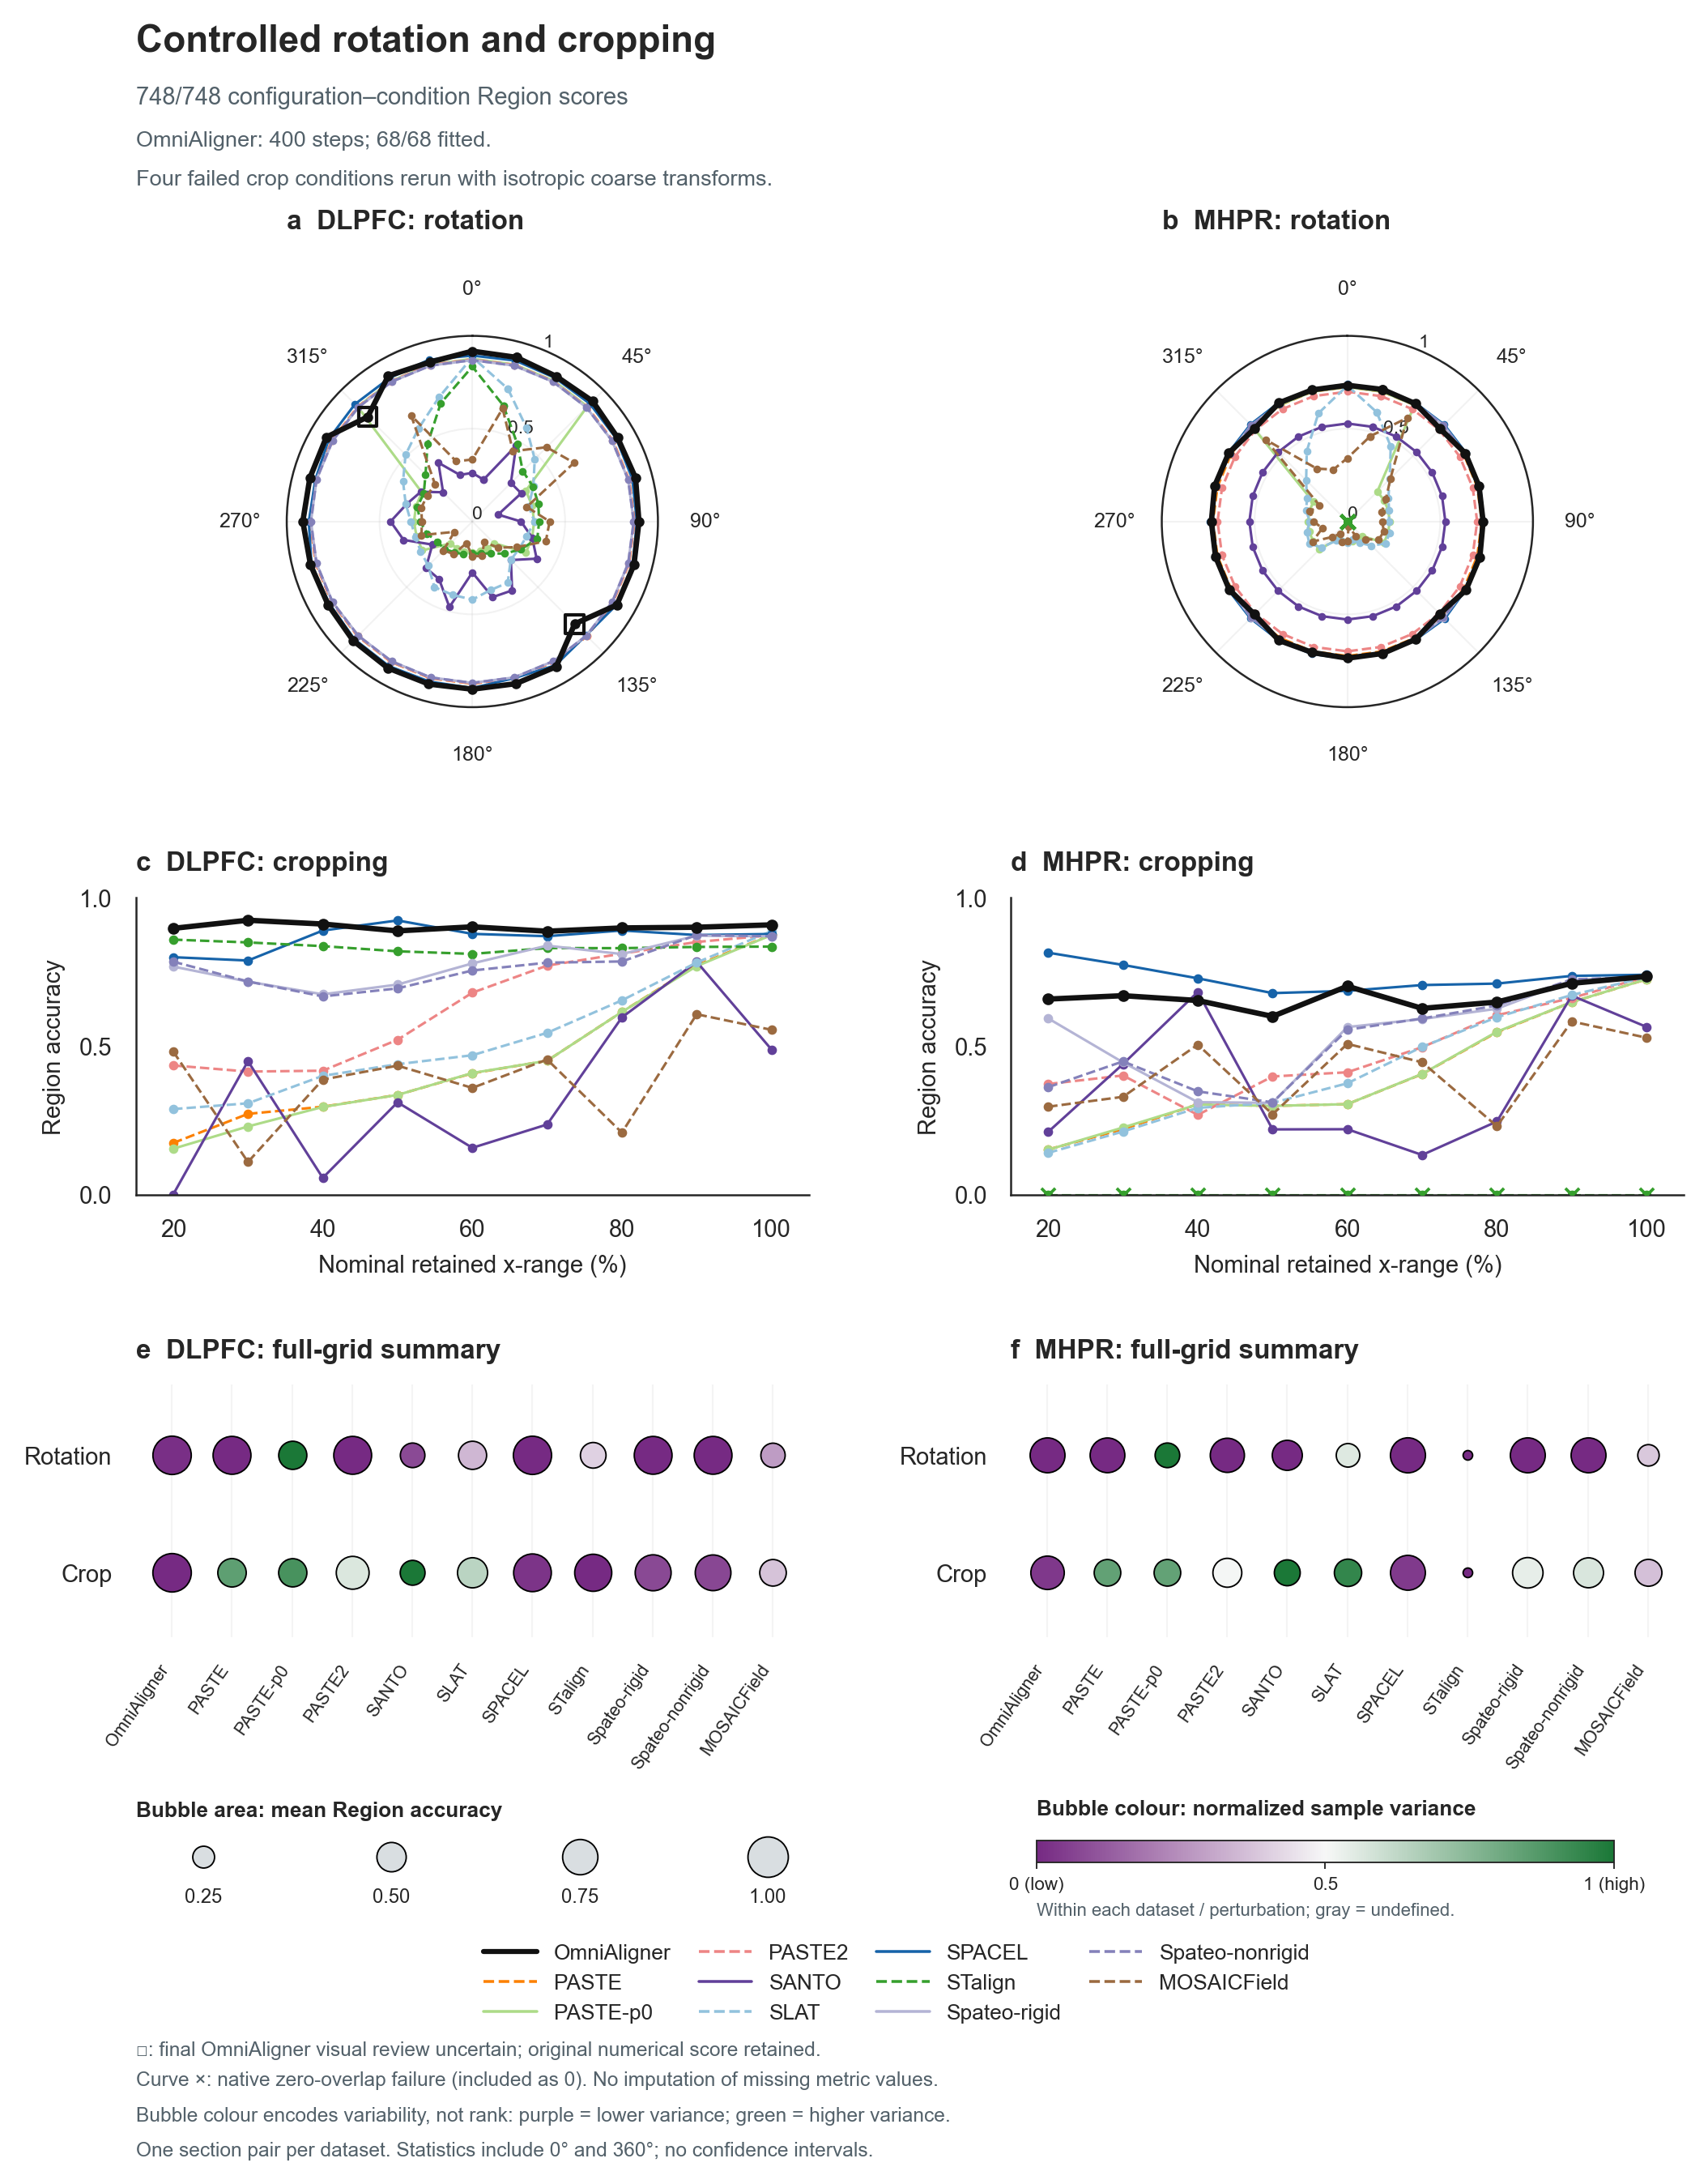

In [17]:
key = fig.add_axes([.085,.126,.43,.049]); key.set(xlim=(0,1),ylim=(0,1));key.axis("off")
key.text(0,1,"Bubble area: mean Region accuracy",fontsize=6.3,weight="bold",va="top")
for x,value in zip([.09,.34,.59,.84],[.25,.5,.75,1.]):
    key.scatter(x,.48,s=bubble_area(value),color="#D9DEE1",edgecolors="black",linewidth=.45)
    key.text(x,.02,f"{value:.2f}",fontsize=5.7,ha="center",va="bottom")
barax=fig.add_axes([.60,.147,.33,.010])
bar=fig.colorbar(ScalarMappable(norm=Normalize(0,1),cmap=cmap),cax=barax,orientation="horizontal",ticks=[0,.5,1])
bar.ax.set_xticklabels(["0 (low)","0.5","1 (high)"]);bar.ax.tick_params(labelsize=5.4,length=2,width=.45,pad=2)
bar.outline.set_linewidth(.45)
fig.text(.60,.169,"Bubble colour: normalized sample variance",fontsize=6.3,weight="bold")
fig.text(.60,.123,"Within each dataset / perturbation; gray = undefined.",fontsize=5.3,color="#53616A")
handles=[Line2D([],[],color=COLOURS[m],ls=STYLES[m],lw=1.5 if m=="OmniAligner" else .85,label=m) for m in METHODS]
fig.legend(handles=handles,loc="lower center",bbox_to_anchor=(.52,.065),ncol=4,fontsize=6.3,columnspacing=1.3,handlelength=2.5)
fig.text(.085,.059,"□: final OmniAligner visual review uncertain; original numerical score retained.",fontsize=5.9,color="#53616A")
fig.text(.085,.045,"Curve ×: native zero-overlap failure (included as 0). No imputation of missing metric values.",fontsize=5.9,color="#53616A")
fig.text(.085,.029,"Bubble colour encodes variability, not rank: purple = lower variance; green = higher variance.",fontsize=5.9,color="#53616A")
fig.text(.085,.013,"One section pair per dataset. Statistics include 0° and 360°; no confidence intervals.",fontsize=5.9,color="#53616A")
for suffix in ["pdf","svg","png"]:
    fig.savefig(OUTPUT_ROOT/f"OmniAligner_rotation_crop.{suffix}",dpi=300,facecolor="white",bbox_inches="tight")
om.pl.plt.close(fig)
pd.DataFrame(curve_rows).to_csv(OUTPUT_ROOT/"curve_source.csv",index=False)
pd.DataFrame(bubble_rows).to_csv(OUTPUT_ROOT/"bubble_source.csv",index=False)
display(Image(filename=str(OUTPUT_ROOT/"OmniAligner_rotation_crop.png")))

## Exported results and calculation scope

`perturbation_reproduced/` now contains all configuration scores, all per-gene
scores, OmniAligner ranks, and editable PDF/SVG plus PNG figures. DLPFC crop 20%
and 30% retain undefined PCC / cosine / SSIM endpoints from the frozen full gene
list; they are not replaced by subset-gene means.

Source: [SABench metric code](https://github.com/Yunzhi-Yan/SABench/blob/54d4e17c6dff5eab7ad93fee2a9bd70385ac750b/Tutorial/SABench.py)
and [robustness plotting notebook](https://github.com/Yunzhi-Yan/SABench/blob/54d4e17c6dff5eab7ad93fee2a9bd70385ac750b/Plot/robustness.ipynb).
The released NPZ manifest records checksums, protocols and original score bindings.
This computational replay verifies the released results; it is not independent
biological validation or a fresh registration / training experiment.

In [18]:
import importlib.metadata
validation = dict(configuration_conditions=len(scores),condition_metric_positions=len(scores)*6,
    gene_metric_positions=len(gene_scores)*5,all_values_match_declared_tolerances=True,
    all_NA_positions_match_exactly=True,metric_absolute_tolerances=ATOL,
    all_eligibility_flags_match=True,all_OmniAligner_ranks_and_counts_match=True,
    OmniAligner_fitted_conditions=len(ranks),OmniAligner_eligible_endpoints=eligible,
    OmniAligner_first_endpoints=first,archive_sha256=sha256(archive),
    environment={name:importlib.metadata.version(name) for name in
                 ["numpy","scipy","pandas","scikit-learn","matplotlib","seaborn"]},
    figure_font_family=om.pl.plt.rcParams["font.family"],pdf_fonttype=om.pl.plt.rcParams["pdf.fonttype"],
    ps_fonttype=om.pl.plt.rcParams["ps.fonttype"])
(OUTPUT_ROOT/"VALIDATION.json").write_text(json.dumps(validation,indent=2)+"\n")
display(pd.Series(validation).drop("environment"))

configuration_conditions                                                                748
condition_metric_positions                                                             4488
gene_metric_positions                                                                519860
all_values_match_declared_tolerances                                                   True
all_NA_positions_match_exactly                                                         True
metric_absolute_tolerances                {'PCC': 1e-10, 'CosSim': 9.5367431640625e-07, ...
all_eligibility_flags_match                                                            True
all_OmniAligner_ranks_and_counts_match                                                 True
OmniAligner_fitted_conditions                                                            68
OmniAligner_eligible_endpoints                                                          402
OmniAligner_first_endpoints                                                     